In [1]:
"""
Examples of ``TableSheet`` (synthetic data).

Run it from the folder that contains ``helpers_ps``::

    python example_sheet.py

Three images are written to ``./out``.
"""

from __future__ import annotations

from pathlib import Path

import numpy as np
import pandas as pd
from matplotlib.figure import Figure

from helpers_ps.DfStyling import TableSheet
import helpers_ps as hp

OUT = Path("out")

In [2]:


# ---------------------------------------------------------------------
# Synthetic data
# ---------------------------------------------------------------------
rng = np.random.default_rng(7)
tenors = ["1M", "3M", "6M", "1Y", "3Y", "5Y", "10Y"]
ratings = ["AAA", "AA+", "AA", "A"]


def make_block(label: str) -> pd.DataFrame:
    index = pd.MultiIndex.from_tuples(
        [(label, period, rating) for period in ("MTD", "YTD") for rating in ratings]
    )
    return pd.DataFrame(
        rng.integers(-25, 40, (len(index), len(tenors))),
        index=index,
        columns=tenors,
    )


df_yield = make_block("Δ Yield")
df_spreads = make_block("Δ Spreads")

RED, GREEN = "#C0392B", "#1E8449"
SIGN_COLORS = {(-np.inf, 0): GREEN, (0, np.inf): RED}

HEADER = {"color": "white", "background-color": "#12275A", "font-weight": "bold"}


def yield_curve_figure() -> Figure:
    """A chart as a plain matplotlib Figure (a GraphMtplt works the same way)."""
    fig = Figure(figsize=(6.5, 3.6))
    ax = fig.subplots()
    x = ["3Y", "5Y", "7Y", "10Y"]
    ax.plot(x, [4.15, 4.65, 5.87, 6.99], color="#12275A", lw=2, label="28 oct. 2026")
    ax.plot(x, [4.20, 4.53, 4.80, 5.85], color="#B7331F", lw=2, label="31 dic. 2025")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    return fig


# ---------------------------------------------------------------------
# 1) One table
# ---------------------------------------------------------------------
sheet_one = (
    TableSheet(df_yield, width_in=7)
    .style_table(
        font_family="Inter, Arial",
        font_size=6,
        text_align="center",
        header_styles=HEADER,
        row_index_styles=[
            {
                "values": "Δ Yield",
                "level": 0,
                "styles": {"background-color": "#B7331F", "color": "white"},
            }
        ],
        show_index_names=False,
    )
    .border_rows([("Δ Yield", "MTD", "A")])
    .text_color_by_range(SIGN_COLORS)
    .panel(
        title="Variación de rendimientos",
        subtitle="Puntos básicos (pb)",
        notes="MTD: mes a la fecha. YTD: año a la fecha.",
    )
    .add_source("Fuente: PIP")
)
sheet_one.save(OUT / "1_una_tabla.png")

# ---------------------------------------------------------------------
# 2) Two tables side by side and a chart underneath
# ---------------------------------------------------------------------
sheet_grid = TableSheet({"yield": df_yield, "spreads": df_spreads}, width_in=13)

# .on() with no arguments selects every panel: same look for both tables.
sheet_grid.on().style_table(
    font_family="Inter, Arial",
    font_size=7,
    text_align="center",
    header_styles=HEADER,
    show_index_names=False,
).text_color_by_range(SIGN_COLORS)

# Then each table gets its own details.
sheet_grid.on("yield").border_rows([("Δ Yield", "MTD", "A")]).panel(
    title="Δ Yield", subtitle="Puntos básicos"
)
sheet_grid.on("spreads").border_rows([("Δ Spreads", "MTD", "A")]).panel(
    title="Δ Spreads", subtitle="Puntos básicos"
)

(
    sheet_grid.add_image(yield_curve_figure(), name="curve")  # becomes active
    .panel(title="Curva de rendimientos soberanos PEN", align="center")  # natural size
    .layout([["yield", "spreads"], ["curve"]])
    .add_title("Renta fija local")
    .add_note("MTD: mes a la fecha. YTD: año a la fecha.")
    .add_source("Fuente: PIP")
    .save(dir=OUT, name="2_dos_tablas_y_grafico")
)

# ---------------------------------------------------------------------
# 3) Same sheet, another arrangement: the tables are not rendered again
# ---------------------------------------------------------------------
(
    sheet_grid.layout([["yield", "spreads", "curve"]])
    .config_layout(width_in=18, col_gap_in=0.4)
    # .save(OUT / "3_en_una_fila.png")
)

print("Imágenes escritas en", OUT.resolve())


Imágenes escritas en D:\Datos de Usuarios\K02066\Desktop\Helpers_PS\helpers_ps\tests\out


In [3]:
df_yield

1M  3M  6M  1Y  3Y  5Y  10Y
Δ Yield MTD AAA  36  15  19  33  12  25   29
            AA+ -11 -22  -6  -7  31  34  -25
            AA    7  28 -17  26 -18   5   28
            A    -6  -3  -7  21  -9  39    3
        YTD AAA   6   7  12  10   8  39   27
            AA+  26  20  15  -3  39   5  -12
            AA   29 -15  30  14 -18 -23    3
            A   -23 -16   8  38   5  27   34

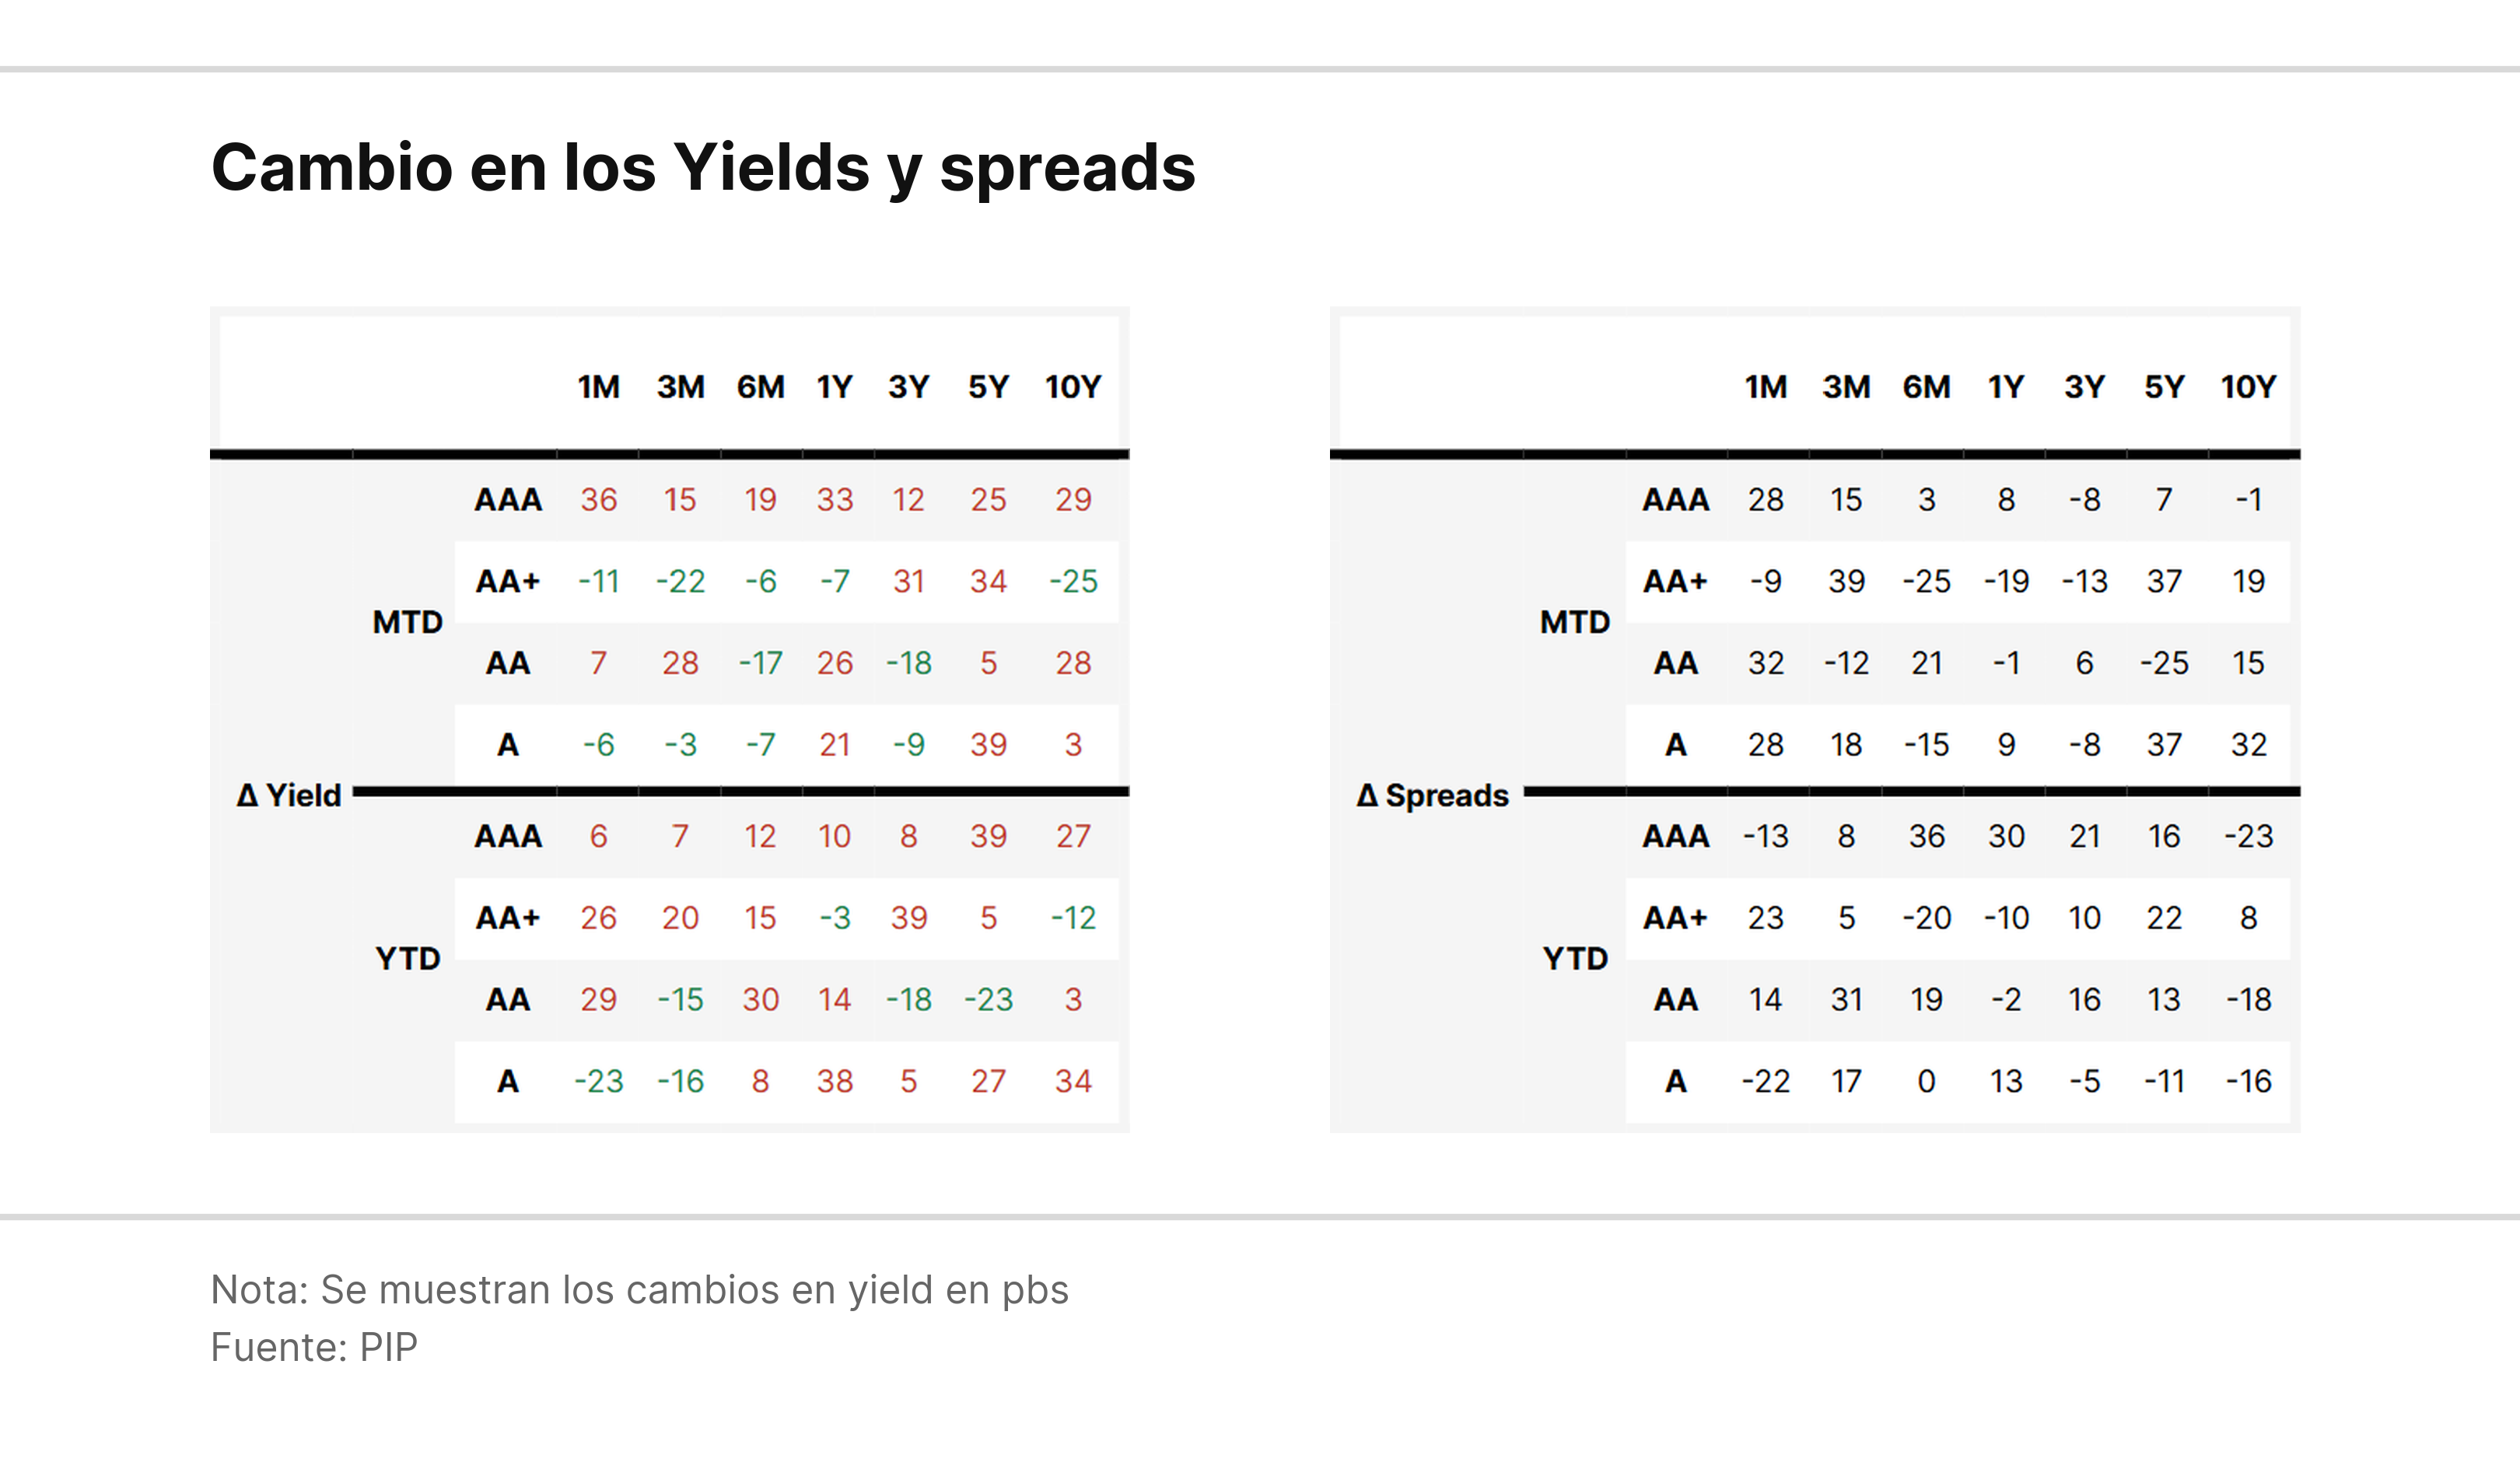

In [14]:
RED, GREEN = "#C0392B", "#1E8449"
SIGN_COLORS = {(-np.inf, 0): GREEN, (0, np.inf): RED}

table_1 = (
    hp.DfStyling.TableSheet(
        dataframe={
            "yield": df_yield, 
            "spreads": df_spreads
        },
        width_in=5.4,
        # height_in=6,
        dpi=600,
        header_size=2,
        line_width=1,
        # width_ratios=[0.5,0.5]
    )
    .layout(ncols=2, width_ratios=[1,1])
    .add_title("Cambio en los Yields y spreads", size=10)
    .add_note("Nota: Se muestran los cambios en yield en pbs", size=6)
    .add_source("Fuente: PIP", size=6)
    .style_table(
        font_family="Inter",
        text_align="center",
        header_styles={"font-size":"3px"},
        row_index_styles=[
            {
                "level": 0,
                "values": "Δ Yield",
                "styles": {"font-size":"3px"}
            },
            {
                "level": 1,
                "values": "MTD",
                "styles": {"font-size":"3px"}
            },
            {
                "level": 1,
                "values": "YTD",
                "styles": {"font-size":"3px"}
            },
            {
                "level": 2,
                "values": ["AAA", "AA", "AA+", "A"],
                "styles": {"font-size":"3px"}
            }
        ],
        data_styles={
            "height":"5px",
            "font-size": "3px"
        },
        corner_styles={"font-size":"3px", "height":"10px"}
    )
    .text_color_by_range(SIGN_COLORS)
    .border_rows([("Δ Yield","MTD", "A")], styles={"width":"0.1px","color":"black"})
    .on("spreads")
    .style_table(
        font_family="Inter",
        text_align="center",
        header_styles={"font-size":"3px"},
        row_index_styles=[
            {
                "level": 0,
                "values": "Δ Spreads",
                "styles": {"font-size":"3px"}
            },
            {
                "level": 1,
                "values": "MTD",
                "styles": {"font-size":"3px"}
            },
            {
                "level": 1,
                "values": "YTD",
                "styles": {"font-size":"3px"}
            },
            {
                "level": 2,
                "values": ["AAA", "AA", "AA+", "A"],
                "styles": {"font-size":"3px"}
            }
        ],
        data_styles={
            "height":"5px",
            "font-size": "3px"
        },
        corner_styles={"font-size":"3px", "height":"10px"}
    )
    .border_rows([("Δ Spreads","MTD", "A")], styles={"width":"0.5px","color":"black"})
    .render()
    .save("prueba.png")
)
display(table_1)